In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('ushape.csv')

In [3]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


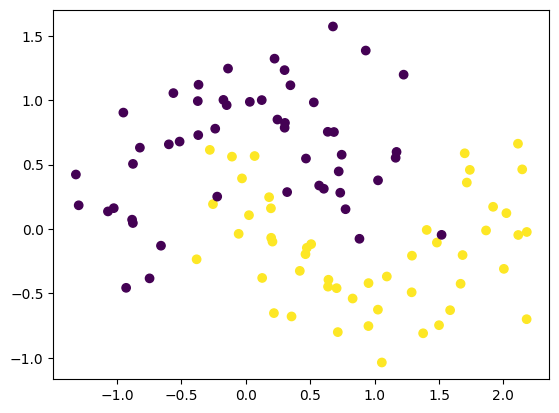

In [5]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [7]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

# Kernel Initializer
We have two types of initializers: 
- Xavier and he_normal. Xavier is beneficial when we are using tanh or sigmoidal function,
-  he_normal is better when we are using ReLU activation function 

In [9]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2,kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

/opt/anaconda3/envs/ml/lib/python3.11/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):
/opt/anaconda3/envs/ml/lib/python3.11/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.get_weights()

[array([[ 1.6549442 , -0.19747408, -0.46875355, -0.1427168 ,  1.3602744 ,
          0.56976175, -0.10677385,  1.4530462 ,  0.07181667, -1.496654  ],
        [-0.07645369,  0.9662952 , -1.2039008 ,  1.2089814 , -2.038496  ,
          1.1820848 ,  1.4521194 , -0.33847243,  0.19552214,  1.6575783 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 6.19961500e-01,  4.76109982e-01, -4.18923885e-01,
         -3.38265538e-01, -1.81779146e-01, -5.65782785e-01,
          7.18826801e-02, -5.94221234e-01,  1.64857551e-01,
          3.67996812e-01],
        [-5.27440906e-01,  7.19329342e-02,  5.58043122e-01,
         -1.94653377e-01, -2.50462979e-01,  5.01500428e-01,
          7.77856588e-01,  7.84570649e-02, -7.26894513e-02,
          2.61050850e-01],
        [ 1.92267939e-01,  2.35862866e-01,  5.12316227e-01,
         -9.22350347e-01,  1.35422826e-01,  7.75837481e-01,
         -3.50945801e-01,  2.10054189e-01, -4.30786133e-01,
         -1.5377567

In [13]:
initial_weights = model.get_weights()

initial_weights[0] = np.random.randn(2,10)*np.sqrt(1/2)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(1/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [15]:
model.set_weights(initial_weights)

In [17]:
model.get_weights()

[array([[-0.3533752 ,  0.58563566, -0.6945684 ,  0.50016516,  0.35884312,
          1.3942462 ,  0.20149514,  0.28629556,  0.8047057 , -0.1619884 ],
        [ 0.16740182,  0.46727434, -0.71360123,  0.5299513 ,  0.58750474,
         -0.4087748 , -0.09152762, -0.13710092,  0.04161072,  0.85716677]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.40659955, -0.30254441, -0.11396789,  0.08178949,  0.13376793,
          0.4834083 , -0.11064769,  0.03117589, -0.20672348, -0.41430512],
        [ 0.5164756 ,  0.28654608, -0.3493352 ,  0.38235694,  0.01704841,
         -0.69859254,  0.27975202,  0.11315352, -0.32006454,  0.1323956 ],
        [ 0.10991123,  0.24975789, -0.01998069, -0.40227   ,  0.10658281,
          0.78169435, -0.42721963,  0.0616276 , -0.32842773,  0.32620028],
        [ 0.00857327, -0.34616566, -0.1252643 ,  0.4333897 , -0.3187782 ,
          0.83387697,  0.16207933,  0.4295005 , -0.06540629, -0.24598438],
        [-0.13469

In [19]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
history = model.fit(X,y,epochs=100,validation_split=0.2)


Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.4375 - loss: 0.7097 - val_accuracy: 0.4500 - val_loss: 0.6996
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4625 - loss: 0.7041 - val_accuracy: 0.4500 - val_loss: 0.6927
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4750 - loss: 0.6980 - val_accuracy: 0.5500 - val_loss: 0.6856
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4750 - loss: 0.6923 - val_accuracy: 0.5500 - val_loss: 0.6790
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4875 - loss: 0.6866 - val_accuracy: 0.6000 - val_loss: 0.6729
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5125 - loss: 0.6816 - val_accuracy: 0.7000 - val_loss: 0.6678
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5375 - loss: 0.6780 - val_accuracy: 0.7000 - val_loss: 0.6644
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5375 - loss: 0.6752 - val_accuracy: 0.7000 - val_loss:

In [21]:
model.get_weights()

[array([[-0.2301248 ,  0.6340485 , -1.0331427 ,  0.52482355,  0.37460387,
          1.5072763 ,  0.16526848,  0.22417663,  0.9496956 , -0.15157923],
        [ 0.49748415,  0.29302874, -0.43427262,  0.8333165 ,  0.37562183,
         -0.6753549 , -0.28592306,  0.10085094, -0.09472653,  1.0086315 ]],
       dtype=float32),
 array([ 0.17288455, -0.0915185 , -0.02103307,  0.1137347 , -0.10154605,
         0.1539319 ,  0.04098567, -0.02745535,  0.05472327,  0.11284113],
       dtype=float32),
 array([[ 0.54700524,  0.01685205, -0.11396789,  0.11300053, -0.06901307,
          0.8134372 , -0.2510381 , -0.20414639, -0.20672348, -0.63269615],
        [ 0.5248942 ,  0.4531352 , -0.3493352 ,  0.4455793 ,  0.06037201,
         -0.46815634,  0.21646832, -0.03175588, -0.32006454,  0.04227981],
        [ 0.3368958 ,  0.52684927, -0.01998069, -0.4488702 ,  0.01967724,
          0.97069067, -0.42721963,  0.09631583, -0.32842773,  0.23357292],
        [-0.0361356 , -0.07593571, -0.1252643 ,  0.4874955 , 

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 2s 221us/step


<Axes: >

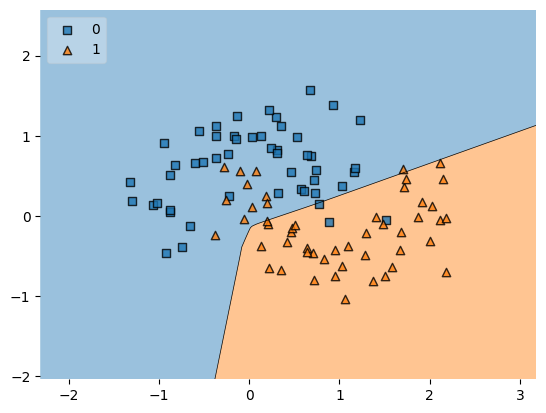

In [23]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X,y.astype('int'), clf=model, legend=2)

In [25]:
(np.random.randn(10,10)*0.01).min()

np.float64(-0.02338721355086297)

In [27]:
(np.random.randn(10,10)*0.01).max()

np.float64(0.02279979037160361)